# 03 - Rede neural (MLP) de regressão: protocolo e baseline

**Problema:** prever `max_heart_rate_achieved` (frequência cardíaca máxima no teste de esforço, em bpm),
com as mesmas 30 features da Atividade 2 (todas as colunas exceto `patient_id` e o target).

Este notebook:
1. monta o protocolo experimental (divisão treino/validação/teste, padronização das features e do target);
2. define a rede (camada de saída e função de perda) e justifica as escolhas;
3. treina a **configuração de referência (baseline)** com 5 sementes e salva o checkpoint do baseline.

A configuração final é escolhida no notebook 05 (estudo de hiperparâmetros e busca aleatória), que também
treina e salva o modelo final (`models/modelo_regressao.pt`).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.config import MODELS, SEMENTES, ler_dataset, indices_split, preparar, salvar_fig, salvar_tabela
from src.models import criar_modelo, n_parametros, macs_por_amostra
from src.train import BASELINE, executar, salvar_checkpoint

torch.set_num_threads(1)  # mesmo nº de threads do estudo de hiperparâmetros (resultados reprodutíveis)
PROBLEMA = "regressao"
print("PyTorch", torch.__version__)

PyTorch 2.14.0+cpu


## 1. Divisão dos dados

- Treino/teste 80/20 **idêntica** à das atividades anteriores (`random_state=42`, estratificada por
  `has_heart_disease`, mesmos índices nos dois problemas).
- Validação = 20% do treino (estratificada, semente 42). Ela é usada para comparar hiperparâmetros,
  para o early stopping e (na classificação) para escolher o limiar. O teste fica guardado até a avaliação final.

In [2]:
df = ler_dataset(PROBLEMA)
idx_tr, idx_val, idx_te, idx_tr_total = indices_split(df)
divisao = pd.DataFrame({
    "conjunto": ["treino", "validação", "teste", "treino + validação"],
    "n": [len(idx_tr), len(idx_val), len(idx_te), len(idx_tr_total)],
    "FC máx. média (bpm)": [df.loc[i, "max_heart_rate_achieved"].mean() for i in (idx_tr, idx_val, idx_te, idx_tr_total)],
    "FC máx. desvio (bpm)": [df.loc[i, "max_heart_rate_achieved"].std() for i in (idx_tr, idx_val, idx_te, idx_tr_total)],
})
salvar_tabela(divisao, "divisao_regressao")
divisao.round(2)

,conjunto,n,FC máx. média (bpm),FC máx. desvio (bpm)
0,treino,5760,164.83,21.32
1,validação,1440,165.20,21.02
2,teste,1800,164.57,21.44
3,treino + validação,7200,164.90,21.26


Conferência: o conjunto de teste é o mesmo da Atividade 2 (mesmos `patient_id`).

In [3]:
from sklearn.model_selection import train_test_split
_, idx_te_at2 = train_test_split(df.index, test_size=0.2, random_state=42, stratify=df["has_heart_disease"])
print("Teste idêntico ao da Atividade 2:", set(idx_te) == set(idx_te_at2))

Teste idêntico ao da Atividade 2: True


## 2. Padronização

Redes neurais são sensíveis à escala: com features em escalas muito diferentes (ex.: `daily_steps` ~ 6.000 e
`hba1c` ~ 6), os gradientes de cada peso ficam em ordens de grandeza diferentes e uma única taxa de aprendizado
não serve a todos. O `StandardScaler` é ajustado **apenas no treino** e aplicado à validação, ao teste e, depois,
à inferência (a média e o desvio vão no checkpoint).

Na regressão o **target também é padronizado** com média e desvio do treino. Sem isso, a rede começaria prevendo
valores perto de 0 para um alvo perto de 165 bpm, com perda MSE inicial da ordem de 27.000, gradientes enormes e
treino instável. As previsões voltam à escala original (bpm) antes de calcular as métricas.

In [4]:
dados = preparar(PROBLEMA)
print(f"Target: média do treino = {dados.y_media:.2f} bpm, desvio = {dados.y_desvio:.2f} bpm")
print(f"Target padronizado - treino: média {dados.y_tr.mean():+.3f}, desvio {dados.y_tr.std():.3f}")
print(f"Target padronizado - validação: média {dados.y_val.mean():+.3f}, desvio {dados.y_val.std():.3f}")
pd.DataFrame({
    "média (treino)": dados.X_tr.mean(0), "desvio (treino)": dados.X_tr.std(0),
    "média (validação)": dados.X_val.mean(0), "desvio (validação)": dados.X_val.std(0),
}, index=dados.features).round(3).head(10)

Target: média do treino = 164.83 bpm, desvio = 21.31 bpm
Target padronizado - treino: média +0.000, desvio 1.000
Target padronizado - validação: média +0.017, desvio 0.986


,média (treino),desvio (treino),média (validação),desvio (validação)
age,-0.0,1.0,-0.007,1.009
sex,-0.0,1.0,0.019,0.999
resting_bp_systolic,0.0,1.0,0.018,1.022
resting_bp_diastolic,0.0,1.0,0.037,1.022
cholesterol_total,0.0,1.0,0.010,1.012
hdl,-0.0,1.0,0.005,1.053
ldl,-0.0,1.0,-0.006,1.000
triglycerides,0.0,1.0,-0.007,1.036
fasting_blood_sugar,0.0,1.0,-0.024,1.025
hba1c,0.0,1.0,0.005,1.029


No treino as features ficam com média 0 e desvio 1 exatos; na validação ficam só próximas disso, porque a
validação foi transformada com as estatísticas do treino (é o que acontece com dados novos na inferência).

## 3. Rede e função de perda

- **Camada de saída:** 1 neurônio linear, sem ativação. O target é contínuo e, depois de padronizado, pode ser
  negativo ou positivo; uma sigmoide ou ReLU na saída limitaria a faixa de valores possíveis.
- **Função de perda:** `nn.MSELoss`. É a perda associada ao erro gaussiano e é coerente com a métrica principal
  (RMSE = raiz do MSE): minimizar o MSE no treino é minimizar diretamente o que é avaliado. MAE e Huber são
  avaliados no estudo de hiperparâmetros (notebook 05).
- **Configuração de referência (baseline):** 2 camadas ocultas de 32 neurônios, ReLU, Adam com
  $\eta = 10^{-3}$, batch 32, até 200 épocas com early stopping (paciência 20, restaura o melhor estado),
  sem weight decay e sem dropout.

In [5]:
print(pd.Series(BASELINE).to_string())
modelo = criar_modelo(BASELINE, len(dados.features))
print(modelo)
print("Parâmetros treináveis:", n_parametros(modelo))
print("MACs por amostra:", macs_por_amostra(len(dados.features), [32, 32]))

neuronios          32
camadas             2
ativacao         ReLU
otimizador       Adam
lr              0.001
batch              32
epocas            200
paciencia          20
weight_decay      0.0
dropout           0.0
perda             MSE
pos_weight        1.0
padronizar       True
MLP(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Parâmetros treináveis: 2081
MACs por amostra: 2016


Parâmetros: (30×32 + 32) + (32×32 + 32) + (32×1 + 1) = 992 + 1.056 + 33 = **2.081**.

## 4. Treino do baseline (5 sementes)

A semente controla a inicialização dos pesos e a ordem dos batches. Cada configuração é treinada com as
5 sementes e reportada como média ± desvio.

In [6]:
resultados, historicos, modelos = [], [], []
for s in SEMENTES:
    r, h, m = executar(BASELINE, dados, s, retornar_modelo=True)
    resultados.append(r); historicos.append(h); modelos.append(m)
res = pd.DataFrame(resultados)
cols = ["seed", "melhor_epoca", "epocas_executadas", "tempo_treino_s", "treino_RMSE", "val_RMSE",
        "treino_MAE", "val_MAE", "treino_R2", "val_R2"]
res[cols].round(3)

,seed,melhor_epoca,epocas_executadas,tempo_treino_s,treino_RMSE,val_RMSE,treino_MAE,val_MAE,treino_R2,val_R2
0,0,6,26,2.803,11.528,11.912,9.172,9.532,0.707,0.679
1,1,5,25,2.644,11.565,11.723,9.217,9.325,0.706,0.689
2,2,3,23,2.436,11.676,11.902,9.313,9.549,0.700,0.679
3,3,2,22,2.343,11.900,11.869,9.495,9.524,0.688,0.681
4,4,6,26,2.757,11.524,11.816,9.173,9.490,0.708,0.684


In [7]:
resumo = res[cols[1:]].agg(["mean", "std"]).T
resumo.columns = ["média", "desvio"]
salvar_tabela(res, "baseline_regressao_sementes")
resumo.round(3)

,média,desvio
melhor_epoca,4.400,1.817
epocas_executadas,24.400,1.817
tempo_treino_s,2.596,0.200
treino_RMSE,11.639,0.158
val_RMSE,11.844,0.078
treino_MAE,9.274,0.136
val_MAE,9.484,0.092
treino_R2,0.702,0.008
val_R2,0.682,0.004


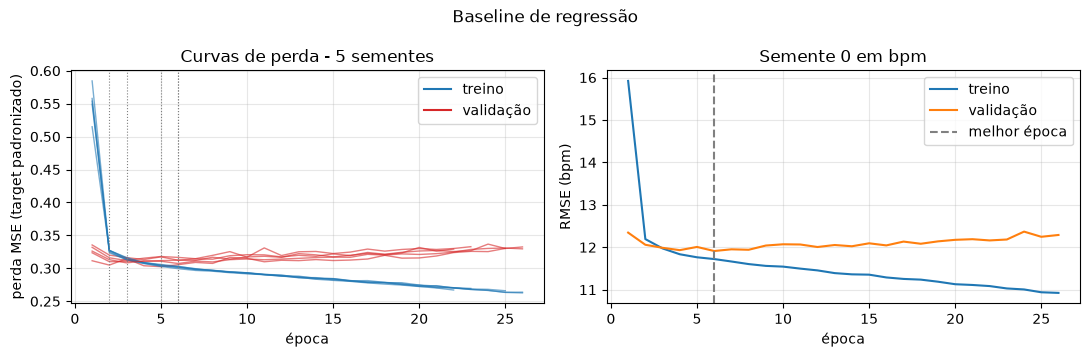

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for s, h in zip(SEMENTES, historicos):
    axes[0].plot(range(1, len(h["treino"]) + 1), h["treino"], color="#1f77b4", alpha=0.6, lw=1)
    axes[0].plot(range(1, len(h["val"]) + 1), h["val"], color="#d62728", alpha=0.6, lw=1)
axes[0].plot([], [], color="#1f77b4", label="treino"); axes[0].plot([], [], color="#d62728", label="validação")
for r in resultados:
    axes[0].axvline(r["melhor_epoca"], color="gray", ls=":", lw=0.8)
axes[0].set(xlabel="época", ylabel="perda MSE (target padronizado)", title="Curvas de perda - 5 sementes")
axes[0].legend(); axes[0].grid(alpha=0.3)
h = historicos[0]
ep = np.arange(1, len(h["treino"]) + 1)
axes[1].plot(ep, np.sqrt(h["treino"]) * dados.y_desvio, label="treino")
axes[1].plot(ep, np.sqrt(h["val"]) * dados.y_desvio, label="validação")
axes[1].axvline(resultados[0]["melhor_epoca"], color="gray", ls="--", label="melhor época")
axes[1].set(xlabel="época", ylabel="RMSE (bpm)", title="Semente 0 em bpm")
axes[1].legend(); axes[1].grid(alpha=0.3)
fig.suptitle("Baseline de regressão"); fig.tight_layout()
salvar_fig("baseline_curvas_regressao")
plt.show()

A perda de validação atinge o mínimo muito cedo (melhor época entre 2 e 6, média 4,4) e depois sobe devagar enquanto a perda
de treino continua caindo: a rede começa a memorizar o treino. O early stopping devolve os pesos do ponto de
mínimo da validação. Com a média do treino como previsão, o RMSE seria igual ao desvio do target (~21,3 bpm);
o baseline fica em 11,84 ± 0,08 bpm na validação (R² = 0,68).

## 5. Checkpoint do baseline

O checkpoint do baseline é salvo para servir de referência na avaliação final (notebook 07), onde baseline e
configuração final são comparados lado a lado no teste. Entre as 5 sementes, guarda-se a de **menor RMSE de
validação** (o teste não é consultado).

In [9]:
i_melhor = int(res["val_RMSE"].idxmin())
print("Semente escolhida:", SEMENTES[i_melhor], "| RMSE de validação:", round(res.loc[i_melhor, "val_RMSE"], 3))
salvar_checkpoint(modelos[i_melhor], BASELINE, dados, MODELS / "baseline_regressao.pt",
                  extras={"seed": SEMENTES[i_melhor], "historico": historicos[i_melhor]})
print("Salvo em", MODELS / "baseline_regressao.pt")

Semente escolhida: 1 | RMSE de validação: 11.723
Salvo em C:\Users\Halyson\Documents\Projetos\Faculdade\IA-MINE\atividade_03\models\baseline_regressao.pt
